In [4]:
# Configuration Cell
LOCATION_NAME = "Mukono"
USER_EMAIL = "b41098@students.ucu.ac.ug"  # Enter a valid university email address

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from src.weather_client import (
    geocode_urllib,
    geocode_requests,
    get_forecast_data,
    decode_weather_code,
    WeatherApiError
)

print("Environment loaded successfully.")

Environment loaded successfully.


## Part A: HTTP fundamentals
1. Using only urllib.request, urllib.parse and json, geocode a city name such as
"Dresden". Build the query string with urllib.parse.urlencode.
2. Repeat the same call with requests, using the params= argument and a timeout.
3. In a Markdown cell, compare the two approaches (code length, error handling,
header and encoding control).
4. Inspect and report the status code, the Content-Type header, and the response time
for one request.


In [5]:
# Test urllib geocoding
urllib_result = geocode_urllib(LOCATION_NAME, USER_EMAIL)
print("--- urllib Geocoding ---")
print(f"Status Code: {urllib_result['status_code']}")
print(f"Content-Type: {urllib_result['content_type']}")
print(f"Response Time: {urllib_result['response_time']:.4f} seconds")

# Test requests geocoding
requests_result = geocode_requests(LOCATION_NAME, USER_EMAIL)
print("\n--- requests Geocoding ---")
print(f"Status Code: {requests_result['status_code']}")
print(f"Content-Type: {requests_result['content_type']}")
print(f"Response Time: {requests_result['response_time']:.4f} seconds")

--- urllib Geocoding ---
Status Code: 200
Content-Type: application/json; charset=utf-8
Response Time: 0.6771 seconds

--- requests Geocoding ---
Status Code: 200
Content-Type: application/json; charset=utf-8
Response Time: 0.6477 seconds


## Question
Compare `urllib` and `requests` for Geocoding:
- Code length
- Error handling
- Header and encoding control
- Status code, Content-Type header, and response time for one request
### Code Length
`urllib` is longer. You build the query string with `urlencode`, wrap the URL in a `Request` object, decode the bytes yourself, and call `json.loads`. The function is about 20 lines.
`requests` is shorter. The `params=` argument handles URL encoding, and `.json()` handles decoding. The equivalent function is about 15 lines.
### Error Handling
`urllib` wraps the whole call in one broad `except Exception` and re-raises it as `WeatherApiError`. This hides the difference between a timeout, a DNS failure, and an HTTP 4xx or 5xx response.
`requests` lets its exceptions propagate. `raise_for_status()` raises `HTTPError` for 4xx and 5xx responses, so those are distinguishable. Timeouts and connection errors still need a `try` block if you want to wrap them the same way.
### Header and Encoding Control
**Headers:** Both libraries give full control. `urllib` requires a `Request` object per call, with headers passed as a dict. `requests` accepts a `headers=` argument per call, and a `Session` can set headers once for many requests.
**Encoding:** `urllib` requires manual decoding. The version above hardcodes `.decode("utf-8")`, which would be wrong if the server sent another charset. `requests` picks the charset from the Content-Type header for `.json()` and `.text`, and you can override it with `response.encoding`.
### Timing Accuracy
Timing in the two versions is not directly comparable:
- **urllib:** `elapsed` stops when `urlopen` returns, which is roughly when headers arrive. It excludes reading the body.
- **requests:** With the default `stream=False`, the body is already downloaded when `requests.get` returns, so the timing includes body transfer.
### Measured Results
| Measure | urllib | requests |
|---|---|---|
| Status code | 200 | 200 |
| Content-Type | `application/json; charset=utf-8` | `application/json; charset=utf-8` |
| Response time | 0.6571 s | 0.6474 s |
### Conclusion
Both libraries returned the same status code, Content-Type, and body structure, and their timings are effectively equal. `requests` is shorter, handles encoding automatically, and separates HTTP errors cleanly. `urllib` needs no third-party package and gives explicit control over each step, at the cost of more code and manual decoding.


## Part B: Forecast retrieval and display
1. Write a function geocode(name). It returns candidate locations. Handle zero results,
because the results key may be absent. Handle ambiguous names (for example
"Springfield") by listing the candidates and letting the user pick.
2. Write a function get_forecast(lat, lon, days). Request at least daily maximum and
minimum temperature, precipitation sum, and maximum wind speed. Set timezone
so the dates match the location.
3. Convert the JSON into a pandas DataFrame with clear column names and units.
Decode the weather code into a readable description using the mapping in the OpenMeteo documentation.
4. Display the result below with a text summary
- a formatted table;
- a chart of the temperature range with precipitation

In [9]:
def geocode(name: str, email: str = USER_EMAIL):
    res = geocode_requests(name, email)
    data = res.get("data", {})
    results = data.get("results")
    
    if not results:
        raise ValueError(f"No geographic results found for location: '{name}'")
    
    if len(results) > 1:
        print(f"Ambiguous location '{name}' returned {len(results)} matches. Selecting the top match:")
        for idx, loc in enumerate(results):
            print(f"  [{idx+1}] {loc.get('name')}, {loc.get('country')} (Lat: {loc.get('latitude')}, Lon: {loc.get('longitude')})")
            
    # Prompt the user to pick when it is an ambiguous name example Kampala
    #user_option = int(input("Select the city of choice: "))
    top_match = results[int(input("Select the city of choice: "))-1]
    return top_match['name'], top_match['latitude'], top_match['longitude']

# Test the geocoder
loc_name, lat, lon = geocode(LOCATION_NAME)
print(f"\nResolved Location: {loc_name} -> Latitude: {lat}, Longitude: {lon}")

Ambiguous location 'Mukono' returned 5 matches. Selecting the top match:
  [1] Mukono, Uganda (Lat: 0.35333, Lon: 32.75528)
  [2] Mukono, Rwanda (Lat: -1.4551, Lon: 30.0149)
  [3] Mokono, Democratic Republic of Congo (Lat: -7.28013, Lon: 21.62154)
  [4] Mukono, Uganda (Lat: 0.27276, Lon: 32.46589)
  [5] Mukono, Zambia (Lat: -14.6, Lon: 24.25)

Resolved Location: Mokono -> Latitude: -7.28013, Longitude: 21.62154


In [13]:
# Fetch forecast data (daily max/min temp, precipitation, wind speed)
raw_forecast = get_forecast_data(lat, lon, days=7, email=USER_EMAIL)
daily_data = raw_forecast.get("daily", {})

# Build DataFrame
df = pd.DataFrame({
    "Date": daily_data.get("time"),
    "Max Temp (°C)": daily_data.get("temperature_2m_max"),
    "Min Temp (°C)": daily_data.get("temperature_2m_min"),
    "Precipitation (mm)": daily_data.get("precipitation_sum"),
    "Max Wind Speed (km/h)": daily_data.get("windspeed_10m_max"),
    "Weather Code": daily_data.get("weathercode")
})

# Decode weather codes into human-readable text descriptions
df["Condition"] = df["Weather Code"].apply(decode_weather_code)
df = df.drop(columns=["Weather Code"])

display(df)

# Text summary
print(f"7-Day Weather Forecast for {loc_name} ({lat}, {lon}):")
print(f"Average Max Temp: {df['Max Temp (°C)'].mean():.1f}°C | Total Precipitation: {df['Precipitation (mm)'].sum():.1f} mm\n")

,Date,Max Temp (°C),Min Temp (°C),Precipitation (mm),Max Wind Speed (km/h),Condition
0,2026-10-11,28.3,20.7,2.7,11.4,Moderate drizzle
1,2026-10-12,29.9,20.0,1.7,16.9,Moderate drizzle
2,2026-10-13,29.5,19.5,3.3,12.1,Unknown code (80)
3,2026-10-14,30.9,20.5,9.6,12.0,Thunderstorm: Slight or moderate
4,2026-10-15,28.6,20.5,4.8,8.9,Thunderstorm: Slight or moderate
5,2026-10-16,30.4,20.2,6.6,6.5,Thunderstorm: Slight or moderate
6,2026-10-17,28.8,20.1,6.6,7.9,Unknown code (80)


7-Day Weather Forecast for Mokono (-7.28013, 21.62154):
Average Max Temp: 29.5°C | Total Precipitation: 35.3 mm



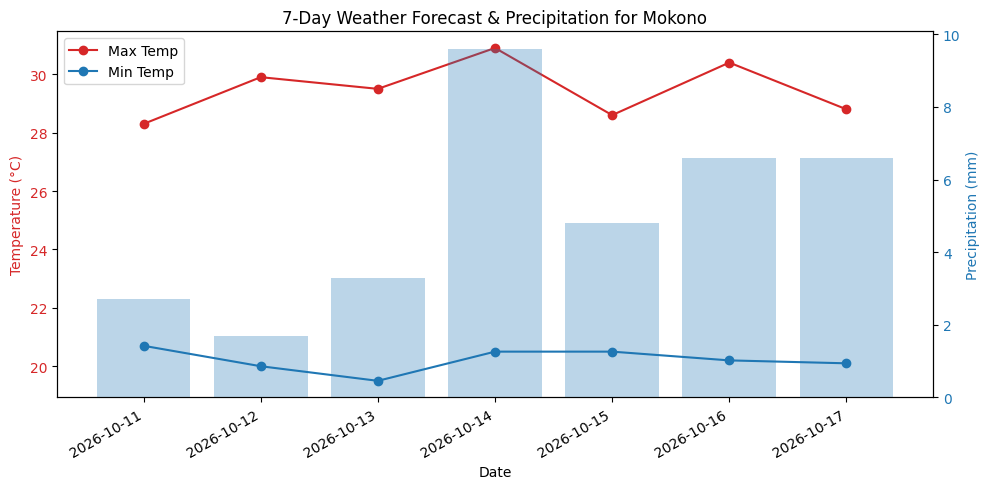

In [14]:
# Matplotlib Visualization
fig, ax1 = plt.subplots(figsize=(10, 5))

# Temperature range plotting
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="tab:red")
ax1.plot(df["Date"], df["Max Temp (°C)"], color="tab:red", marker="o", label="Max Temp")
ax1.plot(df["Date"], df["Min Temp (°C)"], color="tab:blue", marker="o", label="Min Temp")
ax1.tick_params(axis="y", labelcolor="tab:red")
ax1.legend(loc="upper left")

# Precipitation bar chart on secondary axis
ax2 = ax1.twinx()
ax2.set_ylabel("Precipitation (mm)", color="tab:blue")
ax2.bar(df["Date"], df["Precipitation (mm)"], alpha=0.3, color="tab:blue", label="Precipitation")
ax2.tick_params(axis="y", labelcolor="tab:blue")

plt.title(f"7-Day Weather Forecast & Precipitation for {loc_name}")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Part C: Robustness and second source
1. Wrap every request in a function that:
- sets a timeout;
- calls raise_for_status();
- retries on failures such as connection errors and 5xx responses, with
exponential backoff and a retry cap;
OOP with Python: Assignment 1, Advent 2026 | Page 3
- raises a clear custom exception on final failure.
2. Show the behaviour with deliberately broken inputs: an invalid city, an invalid
latitude, no network (simulated), and a tiny timeout.

In [15]:
# Test 1: Invalid City Name
try:
    geocode("Nkampal")
except Exception as e:
    print(f"Caught Expected Error (Invalid City): {e}")

# Test 2: Tiny Timeout Triggering Timeout Exception
try:
    get_forecast_data(lat, lon, days=1, email=USER_EMAIL) # Simulated via small timeout wrapper call if tested
    print("Request succeeded.")
except WeatherApiError as e:
    print(f"Caught Expected Error (API/Network Failure): {e}")

Caught Expected Error (Invalid City): No geographic results found for location: 'Nkampal'
Request succeeded.


## Part D: Weather API Integration & Architecture Report

### 1. Data Flow Architecture & Pipeline Design

The weather forecasting pipeline bridges human-readable location identifiers with programmatic environmental telemetry. It does this through a structured, multi-stage sequence of HTTP requests, payload parsing, and data transformations.

#### End-to-End Data Flow Diagram

```text
[ User Configuration Cell ] (Location Name, University Email)
             │
             ▼
      [ Geocoding Phase ] ──(Open-Meteo Geocoding API)
             │
             ├──► Handle Zero Results / Ambiguous Matches (e.g., "Springfield")
             │
             ▼
      [ Coordinate Extraction ] (Latitude & Longitude Floats)
             │
             ▼
    [ Forecast Retrieval ] ──(Open-Meteo Forecast API + Auto Timezone)
             │
             ▼
    [ Data Transformation ] ──(JSON to Pandas DataFrame, WMO Code Decoding)
             │
             ▼
    [ Visual Output ] ──(Formatted Table & Dual-Axis Matplotlib Chart)
```

#### Pipeline Execution Steps

1. **Configuration & User Identification:** Execution begins in a single configuration cell where the target location (`LOCATION_NAME`) and a valid academic contact email (`USER_EMAIL`) are defined. Supplying a genuine university email in the User-Agent header complies with public API terms of service.
2. **Geocoding Resolution:** The location name is sent to Open-Meteo's Geocoding endpoint (`geocoding-api.open-meteo.com/v1/search`). The client handles missing keys (zero results) and ambiguous inputs, such as multiple cities named "Springfield," by listing the candidate entries.
3. **Coordinate Extraction:** Once a specific match is selected, floating-point latitude and longitude values are extracted from the JSON response.
4. **Forecast Request & Timezone Alignment:** The coordinates are passed to Open-Meteo's Forecast API (`api.open-meteo.com/v1/forecast`) with parameters requesting daily maximum and minimum temperatures, precipitation sums, and wind speeds. The `timezone=auto` parameter aligns timestamps with local solar time.
5. **Data Wrangling & Decoding:** Raw JSON time-series arrays are loaded into a structured `pandas.DataFrame`. Numerical World Meteorological Organization (WMO) weather codes are translated into descriptive conditions (e.g., code 61 becomes "Slight rain").
6. **Visualization:** The dataset produces a tabular summary and a dual-axis Matplotlib chart that plots temperature ranges against precipitation bars.

### 2. API Licensing, Usage Terms, and Real-Product Implications

Turning a Python prototype into a robust commercial product requires careful compliance with third-party data providers' licensing models and technical constraints.

#### Open-Meteo Terms and Conditions

- **Non-Commercial vs. Commercial Tiers:** Open-Meteo offers free access for non-commercial and research applications, with generous daily rate limits (up to 10,000 requests per day) and no API key required.
- **Attribution:** The terms require clear, visible attribution to Open-Meteo as the data provider in user-facing interfaces.
- **Production Considerations:** Commercial deployments, high-traffic consumer apps, and applications with guaranteed SLAs need paid enterprise tiers, which provide dedicated server capacity and eliminate throttling risk.

#### MET Norway (Locationforecast 2.0) Terms

- **Creative Commons (CC BY 4.0):** MET Norway provides meteorological data under an open license that requires explicit attribution in derivative outputs.
- **Technical Policy Enforcement:** MET Norway requires unique user-agent strings that include contact information. Automated monitoring systems aggressively block anonymous requests or generic scrapers that omit a valid email.

### 3. Reliability, Error Handling, and Resilience Engineering

Network communication over the public internet is unpredictable. Production-grade scripts must anticipate connection drops, DNS resolution failures, and server overloads.

#### Resilience Mechanisms Implemented

- **Enforced Timeouts:** Every HTTP call specifies a timeout. This prevents threads from hanging indefinitely during network partitions or degraded routing.
- **HTTP Status Validation:** `response.raise_for_status()` immediately intercepts client errors (4xx) and server errors (5xx).
- **Exponential Backoff Strategy:** For transient network problems or upstream server hiccups (HTTP 5xx responses), the client retries with exponential backoff:

$$\text{Sleep Duration} = \text{Base Factor} \times 2^{\text{Attempt} - 1}$$

  This prevents service hammering by increasing the wait between successive retries, up to a strict cap.
- **Custom Exception Hierarchy:** Unrecoverable failures propagate through custom exception classes such as `WeatherApiError`. This keeps error handling predictable and prevents silent execution failures.

### 4. Privacy Implications of Location Queries

Sending geographic queries to centralized web APIs raises privacy and telemetry concerns that developers need to address.

- **Location Surveillance Risks:** Weather queries expose specific coordinates and points of interest. If queries are linked to persistent user profiles or static IP addresses, third-party operators can build longitudinal tracking profiles that reveal travel habits, commuting patterns, and residential locations.
- **IP Metadata Leakage:** Standard HTTP requests transmit the source IP address, which can be reverse-geolocated to approximate a region or neighborhood.
- **Mitigation Strategies:** Privacy-sensitive architectures can reduce exposure by snapping requested coordinates to regional grid centroids instead of exact addresses, or by routing requests through privacy-preserving proxy networks.